# Cottonil Sales Forecasting System

Machine learning sales forecasts from historical Cottonil orders.

**Scenario 1 — Next month:** expected total sales for the next calendar month, for one branch or for the whole company.

**Scenario 2 — Month-end:** expected sales by the end of the latest available month, using actuals-to-date plus a forecast of the remaining days.

The notebook follows the real Cottonil schema (not assumed column names). Preprocessing, feature engineering, training, evaluation, and inference are kept in separate sections. Trained models and cleaned datasets are written to `outputs/`.

## 0. Setup

In [1]:
import subprocess
import sys


def ensure(package, import_name=None):
    name = import_name or package
    try:
        __import__(name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", package, "-q"])


for pkg, alias in [
    ("pandas", None),
    ("numpy", None),
    ("scikit-learn", "sklearn"),
    ("xgboost", None),
    ("matplotlib", None),
    ("seaborn", None),
    ("joblib", None),
    ("statsmodels", None),
]:
    ensure(pkg, alias)

try:
    ensure("prophet", "prophet")
except Exception as exc:
    print("Prophet is optional and was not installed:", exc)


In [2]:
from __future__ import annotations

import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    pass

ROOT = Path.cwd()
DATA_TABLES = ROOT / "COTTONIL_Data" / "02_TABLES"
OUT = ROOT / "outputs"
for sub in ("data", "models", "reports", "figures"):
    (OUT / sub).mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("Tables:", DATA_TABLES.exists())


Project root: E:\HVIA\cottonil model
Tables: True


## 1. Data understanding

Inspect the actual files and columns. Cottonil sales live in `sales_orders.csv` (`order_date`, `branch_id`, `paid_total_EGP`, `net_before_tax_EGP`, `status`). Line-level quantity and product fields are in `sales_order_items.csv` but are not required for branch/company totals. Returns are applied by `return_date` after joining `branch_id` from the original order.

In [3]:
orders_path = DATA_TABLES / "sales_orders.csv"
branches_path = DATA_TABLES / "branches.csv"
returns_path = DATA_TABLES / "sales_returns.csv"

orders = pd.read_csv(orders_path, parse_dates=["order_date"])
branches = pd.read_csv(branches_path)
returns = pd.read_csv(returns_path, parse_dates=["return_date"])
branches["opening_date"] = pd.to_datetime(branches["opening_date"], errors="coerce")

print("sales_orders columns:", list(orders.columns))
print("rows:", len(orders))
print("date range:", orders["order_date"].min().date(), "→", orders["order_date"].max().date())
print("branches in orders:", orders["branch_id"].nunique())
print("\norder status:\n", orders["status"].value_counts())
print("\nsales_channel:\n", orders["sales_channel"].value_counts())
print("\nnull counts:\n", orders.isna().sum())
print("\nbranches columns:", list(branches.columns), "n=", len(branches))
print("returns columns:", list(returns.columns), "n=", len(returns))


sales_orders columns: ['sales_order_id', 'order_date', 'branch_id', 'customer_id', 'sales_channel', 'payment_method', 'items_count', 'gross_EGP', 'discount_EGP', 'net_before_tax_EGP', 'tax_EGP', 'paid_total_EGP', 'status']
rows: 540000
date range: 2018-10-19 → 2026-10-18
branches in orders: 80

order status:
 status
Completed             448120
Delivered              81152
Partially returned     10728
Name: count, dtype: int64

sales_channel:
 sales_channel
Retail POS              388171
E-commerce               97660
Wholesale / reseller     54169
Name: count, dtype: int64

null counts:
 sales_order_id             0
order_date                 0
branch_id                  0
customer_id           102961
sales_channel              0
payment_method             0
items_count                0
gross_EGP                  0
discount_EGP               0
net_before_tax_EGP         0
tax_EGP                    0
paid_total_EGP             0
status                     0
dtype: int64

branches colu

In [4]:
AS_OF_DATE = pd.Timestamp(orders["order_date"].max().normalize())
LATEST_MONTH = AS_OF_DATE.to_period("M")
calendar_today = pd.Timestamp.today().normalize()

print("Latest transaction date in the dataset:", AS_OF_DATE.date())
print("Latest available month:", LATEST_MONTH)
print("Calendar today:", calendar_today.date())
if AS_OF_DATE.to_period("M") != calendar_today.to_period("M"):
    print(
        "Note: the dataset month does not match the real calendar month. "
        "Scenario 2 uses the latest available month, not an invented current month."
    )
else:
    month_days = AS_OF_DATE.days_in_month
    print(
        f"Latest month is the current calendar month and is partial "
        f"({AS_OF_DATE.day} of {month_days} days present)."
    )


Latest transaction date in the dataset: 2026-10-18
Latest available month: 2026-10
Calendar today: 2026-11-01
Note: the dataset month does not match the real calendar month. Scenario 2 uses the latest available month, not an invented current month.


## 2. Preprocessing

- Parse dates; keep completed, delivered, and partially returned orders (there are no cancelled rows).
- **Sales amount** = `paid_total_EGP` (cash collected, including tax).
- **Net sales** = sales amount minus refunds posted on that calendar date.
- Build a complete daily panel per branch from the later of opening date and first order date, filling days with no orders as 0.
- Flag the last month as partial when observed days < calendar days in the month.

In [5]:
TARGET_GROSS = "sales_amount"
TARGET_NET = "net_sales"


def build_daily_panel(orders: pd.DataFrame, branches: pd.DataFrame, returns: pd.DataFrame) -> pd.DataFrame:
    sales = (
        orders.groupby(["order_date", "branch_id"], as_index=False)
        .agg(
            sales_amount=("paid_total_EGP", "sum"),
            net_before_tax=("net_before_tax_EGP", "sum"),
            order_count=("sales_order_id", "nunique"),
            items_count=("items_count", "sum"),
        )
    )
    ret = returns.merge(orders[["sales_order_id", "branch_id"]], on="sales_order_id", how="left")
    ret_daily = (
        ret.dropna(subset=["branch_id"])
        .groupby(["return_date", "branch_id"], as_index=False)
        .agg(refund_amount=("refund_amount_EGP", "sum"))
        .rename(columns={"return_date": "order_date"})
    )
    daily = sales.merge(ret_daily, on=["order_date", "branch_id"], how="outer")
    for col in ["sales_amount", "net_before_tax", "order_count", "items_count", "refund_amount"]:
        daily[col] = daily[col].fillna(0.0)
    daily["order_date"] = pd.to_datetime(daily["order_date"])

    as_of = daily["order_date"].max()
    frames = []
    meta = branches.set_index("branch_id")
    for branch_id, grp in daily.groupby("branch_id"):
        opening = meta.loc[branch_id, "opening_date"] if branch_id in meta.index else grp["order_date"].min()
        start = max(pd.Timestamp(opening), grp["order_date"].min())
        idx = pd.date_range(start, as_of, freq="D")
        g = grp.set_index("order_date").reindex(idx)
        g.index.name = "order_date"
        g["branch_id"] = branch_id
        for col in ["sales_amount", "net_before_tax", "order_count", "items_count", "refund_amount"]:
            g[col] = g[col].fillna(0.0)
        frames.append(g.reset_index())
    panel = pd.concat(frames, ignore_index=True)
    panel["net_sales"] = panel["sales_amount"] - panel["refund_amount"]
    panel = panel.merge(
        branches[["branch_id", "governorate_ar", "retail_location_type", "opening_date", "branch_name_ar"]],
        on="branch_id",
        how="left",
    )
    panel["year_month"] = panel["order_date"].dt.to_period("M")
    panel["dow"] = panel["order_date"].dt.dayofweek
    panel["day"] = panel["order_date"].dt.day
    panel["month"] = panel["order_date"].dt.month
    panel["year"] = panel["order_date"].dt.year
    panel["is_weekend"] = panel["dow"].isin([4, 5]).astype(int)  # Fri-Sat in Egypt
    return panel


daily = build_daily_panel(orders, branches, returns)
print(daily.shape)
print(daily[["sales_amount", "net_sales", "refund_amount"]].sum())
daily.head()


(208368, 18)
sales_amount    938,197,982.25
net_sales       924,584,140.47
refund_amount    13,613,841.78
dtype: float64


,order_date,branch_id,sales_amount,net_before_tax,order_count,items_count,refund_amount,net_sales,governorate_ar,retail_location_type,opening_date,branch_name_ar,year_month,dow,day,month,year,is_weekend
0,2019-09-14,BR001,222.30,195.00,1.00,2.00,0.00,222.30,القاهرة,Point of sale / reseller,2019-09-14,الزمالك,2019-09,5,14,9,2019,1
1,2019-09-15,BR001,0.00,0.00,0.00,0.00,0.00,0.00,القاهرة,Point of sale / reseller,2019-09-14,الزمالك,2019-09,6,15,9,2019,0
2,2019-09-16,BR001,399.27,350.24,2.00,3.00,0.00,399.27,القاهرة,Point of sale / reseller,2019-09-14,الزمالك,2019-09,0,16,9,2019,0
3,2019-09-17,BR001,356.67,312.87,1.00,2.00,0.00,356.67,القاهرة,Point of sale / reseller,2019-09-14,الزمالك,2019-09,1,17,9,2019,0
4,2019-09-18,BR001,77.88,68.32,1.00,1.00,0.00,77.88,القاهرة,Point of sale / reseller,2019-09-14,الزمالك,2019-09,2,18,9,2019,0


In [6]:
def add_partial_month_flag(monthly: pd.DataFrame) -> pd.DataFrame:
    monthly = monthly.copy()
    monthly["month_start"] = monthly["year_month"].dt.to_timestamp()
    monthly["days_in_month"] = monthly["month_start"].dt.days_in_month
    monthly["is_partial"] = monthly["observed_days"] < monthly["days_in_month"]
    return monthly


def build_monthly(daily: pd.DataFrame) -> pd.DataFrame:
    monthly = (
        daily.groupby(["branch_id", "year_month"], as_index=False)
        .agg(
            sales_amount=("sales_amount", "sum"),
            net_sales=("net_sales", "sum"),
            net_before_tax=("net_before_tax", "sum"),
            order_count=("order_count", "sum"),
            items_count=("items_count", "sum"),
            observed_days=("order_date", "nunique"),
            active_days=("sales_amount", lambda s: int((s > 0).sum())),
            governorate_ar=("governorate_ar", "first"),
            retail_location_type=("retail_location_type", "first"),
            opening_date=("opening_date", "first"),
            branch_name_ar=("branch_name_ar", "first"),
        )
    )
    monthly = add_partial_month_flag(monthly)
    monthly["months_since_open"] = (
        (monthly["month_start"].dt.year - monthly["opening_date"].dt.year) * 12
        + (monthly["month_start"].dt.month - monthly["opening_date"].dt.month)
    ).clip(lower=0)
    return monthly.sort_values(["branch_id", "year_month"]).reset_index(drop=True)


def company_monthly_from_branches(monthly: pd.DataFrame) -> pd.DataFrame:
    company = (
        monthly.groupby("year_month", as_index=False)
        .agg(
            sales_amount=("sales_amount", "sum"),
            net_sales=("net_sales", "sum"),
            net_before_tax=("net_before_tax", "sum"),
            order_count=("order_count", "sum"),
            items_count=("items_count", "sum"),
            observed_days=("observed_days", "max"),
            days_in_month=("days_in_month", "max"),
            is_partial=("is_partial", "max"),
        )
    )
    company["branch_id"] = "ALL"
    company["governorate_ar"] = "ALL"
    company["retail_location_type"] = "ALL"
    company["opening_date"] = monthly["opening_date"].min()
    company["branch_name_ar"] = "Company total"
    company["month_start"] = company["year_month"].dt.to_timestamp()
    company["months_since_open"] = (
        (company["month_start"].dt.year - company["opening_date"].dt.year) * 12
        + (company["month_start"].dt.month - company["opening_date"].dt.month)
    )
    return company


monthly_branch = build_monthly(daily)
monthly_company = company_monthly_from_branches(monthly_branch)
monthly_all = pd.concat([monthly_branch, monthly_company], ignore_index=True)

daily.to_csv(OUT / "data" / "daily_sales.csv", index=False)
monthly_all.to_csv(OUT / "data" / "monthly_sales.csv", index=False)

print("Daily rows:", len(daily))
print("Branch-months:", len(monthly_branch), "Company-months:", len(monthly_company))
print("Partial months:\n", monthly_company.loc[monthly_company["is_partial"], ["year_month", "observed_days", "days_in_month"]])
monthly_company.tail()


Daily rows: 208368
Branch-months: 6917 Company-months: 96
Partial months:
    year_month  observed_days  days_in_month
0     2018-11             25             30
1     2018-12             31             31
2     2019-01             31             31
3     2019-02             28             28
4     2019-03             31             31
5     2019-04             30             30
6     2019-05             31             31
7     2019-06             30             30
8     2019-07             31             31
9     2019-08             31             31
10    2019-09             30             30
11    2019-10             31             31
12    2019-11             30             30
13    2019-12             31             31
14    2020-01             31             31
15    2020-02             29             29
16    2020-03             31             31
17    2020-04             30             30
18    2020-05             31             31
19    2020-06             30             30
2

,year_month,sales_amount,net_sales,net_before_tax,order_count,items_count,observed_days,days_in_month,is_partial,branch_id,governorate_ar,retail_location_type,opening_date,branch_name_ar,month_start,months_since_open
91,2026-06,"26,784,625.09","26,425,258.39","23,495,284.72","7,748.00","16,341.00",30,30,False,ALL,ALL,ALL,2018-11-06,Company total,2026-06-01,91
92,2026-07,"28,157,542.58","27,706,201.69","24,699,598.17","8,124.00","16,883.00",31,31,False,ALL,ALL,ALL,2018-11-06,Company total,2026-07-01,92
93,2026-08,"27,178,399.75","26,776,196.20","23,840,700.90","7,983.00","16,867.00",31,31,False,ALL,ALL,ALL,2018-11-06,Company total,2026-08-01,93
94,2026-09,"26,153,301.37","25,738,449.69","22,941,492.26","7,561.00","15,875.00",30,30,False,ALL,ALL,ALL,2018-11-06,Company total,2026-09-01,94
95,2026-10,"16,638,087.13","16,271,453.90","14,594,812.94","4,641.00","9,945.00",18,31,True,ALL,ALL,ALL,2018-11-06,Company total,2026-10-01,95


## 3. Feature engineering

Only information that would be known **before** the target period is used:

- Calendar: month, quarter, year, Fourier seasonality.
- Lags and rolling stats computed with `shift(1)` inside each branch (and the company series).
- Egyptian calendar overlays (Ramadan / Eid windows) that are known in advance.
- Static branch attributes and months since opening.

No same-period sales, campaign performance, or future returns enter the feature set.

In [7]:
RAMADAN = [
    ("2018-05-16", "2018-06-14"),
    ("2019-05-06", "2019-06-04"),
    ("2020-04-24", "2020-05-23"),
    ("2021-04-13", "2021-05-12"),
    ("2022-04-02", "2022-05-01"),
    ("2023-03-23", "2023-04-20"),
    ("2024-03-11", "2024-04-09"),
    ("2025-03-01", "2025-03-30"),
    ("2026-02-17", "2026-03-18"),
    ("2027-02-08", "2027-03-09"),
]
EID_FITR = [
    ("2018-06-15", "2018-06-18"),
    ("2019-06-05", "2019-06-08"),
    ("2020-05-24", "2020-05-27"),
    ("2021-05-13", "2021-05-16"),
    ("2022-05-02", "2022-05-05"),
    ("2023-04-21", "2023-04-24"),
    ("2024-04-10", "2024-04-13"),
    ("2025-03-31", "2025-04-03"),
    ("2026-03-19", "2026-03-22"),
]
EID_ADHA = [
    ("2018-08-21", "2018-08-24"),
    ("2019-08-11", "2019-08-14"),
    ("2020-07-31", "2020-08-03"),
    ("2021-07-20", "2021-07-23"),
    ("2022-07-09", "2022-07-12"),
    ("2023-06-28", "2023-07-01"),
    ("2024-06-16", "2024-06-19"),
    ("2025-06-06", "2025-06-09"),
    ("2026-05-27", "2026-05-30"),
]


def _overlap_days(start, end, ranges) -> int:
    s, e = pd.Timestamp(start), pd.Timestamp(end)
    total = 0
    for a, b in ranges:
        rs, re = pd.Timestamp(a), pd.Timestamp(b)
        lo, hi = max(s, rs), min(e, re)
        if hi >= lo:
            total += (hi - lo).days + 1
    return total


def calendar_monthly_features(year_month: pd.Period) -> dict:
    start = year_month.to_timestamp()
    end = start + pd.offsets.MonthEnd(0)
    month = int(year_month.month)
    return {
        "year": int(year_month.year),
        "month": month,
        "quarter": int(year_month.quarter),
        "month_sin": np.sin(2 * np.pi * month / 12),
        "month_cos": np.cos(2 * np.pi * month / 12),
        "ramadan_days": _overlap_days(start, end, RAMADAN),
        "eid_fitr_days": _overlap_days(start, end, EID_FITR),
        "eid_adha_days": _overlap_days(start, end, EID_ADHA),
        "is_november": int(month == 11),
        "is_summer": int(month in (6, 7, 8)),
        "days_in_month": int(start.days_in_month),
    }


def add_monthly_features(df: pd.DataFrame, target: str = TARGET_GROSS) -> pd.DataFrame:
    df = df.sort_values(["branch_id", "year_month"]).copy()
    cal = df["year_month"].map(calendar_monthly_features)
    cal_df = pd.DataFrame(list(cal), index=df.index)
    overlap = [c for c in cal_df.columns if c in df.columns]
    if overlap:
        df = df.drop(columns=overlap)
    df = pd.concat([df, cal_df], axis=1)
    g = df.groupby("branch_id")[target]
    for lag in (1, 2, 3, 6, 12):
        df[f"lag_{lag}"] = g.shift(lag)
    for win in (3, 6, 12):
        df[f"roll_mean_{win}"] = g.transform(lambda s, w=win: s.shift(1).rolling(w).mean())
        df[f"roll_std_{win}"] = g.transform(lambda s, w=win: s.shift(1).rolling(w).std())
    df["yoy_change"] = df["lag_1"] / df["lag_12"].replace(0, np.nan) - 1
    df["mom_change"] = df["lag_1"] / df["lag_2"].replace(0, np.nan) - 1
    df["expanding_mean"] = g.transform(lambda s: s.shift(1).expanding().mean())
    df = df.replace([np.inf, -np.inf], np.nan)
    for col in ["yoy_change", "mom_change", "roll_std_3", "roll_std_6", "roll_std_12"]:
        if col in df.columns:
            df[col] = df[col].fillna(0.0)
    return df


MONTHLY_NUM = [
    "year", "month", "quarter", "month_sin", "month_cos",
    "ramadan_days", "eid_fitr_days", "eid_adha_days",
    "is_november", "is_summer", "days_in_month", "months_since_open",
    "lag_1", "lag_2", "lag_3", "lag_6", "lag_12",
    "roll_mean_3", "roll_mean_6", "roll_mean_12",
    "roll_std_3", "roll_std_6", "yoy_change", "mom_change", "expanding_mean",
]
MONTHLY_CAT = ["branch_id", "governorate_ar", "retail_location_type"]
MONTHLY_REQUIRED = ["lag_1", "lag_2", "lag_3", "lag_12", "roll_mean_3", "roll_mean_12"]

featured_monthly = add_monthly_features(monthly_all)
featured_complete = featured_monthly.loc[~featured_monthly["is_partial"]].copy()
print("Featured complete months:", len(featured_complete))
featured_complete.head()


Featured complete months: 6832


,branch_id,year_month,sales_amount,net_sales,net_before_tax,order_count,items_count,observed_days,active_days,governorate_ar,retail_location_type,opening_date,branch_name_ar,month_start,is_partial,months_since_open,year,month,quarter,month_sin,month_cos,ramadan_days,eid_fitr_days,eid_adha_days,is_november,is_summer,days_in_month,lag_1,lag_2,lag_3,lag_6,lag_12,roll_mean_3,roll_std_3,roll_mean_6,roll_std_6,roll_mean_12,roll_std_12,yoy_change,mom_change,expanding_mean
6939,ALL,2020-09,"2,113,611.64","2,074,588.58","1,854,044.88","3,398.00","7,246.00",30,NaN,ALL,ALL,2018-11-06,Company total,2020-09-01,False,22,2020,9,3,-1.00,-0.00,0,0,0,0,0,30,"2,190,826.81","2,120,610.36","2,056,541.90","2,068,244.64","1,181,479.26","2,122,659.69","67,165.91","2,129,455.67","57,082.53","1,843,090.34","349,662.46",0.85,0.03,"1,221,993.00"
6940,ALL,2020-10,"2,266,090.66","2,236,529.16","1,987,798.51","3,666.00","7,685.00",31,NaN,ALL,ALL,2018-11-06,Company total,2020-10-01,False,23,2020,10,4,-0.87,0.50,0,0,0,0,0,31,"2,113,611.64","2,190,826.81","2,120,610.36","2,165,010.43","1,299,995.08","2,141,682.94","42,703.46","2,137,016.84","49,906.50","1,920,768.04","287,299.16",0.63,-0.04,"1,260,759.03"
6941,ALL,2020-11,"3,025,235.12","2,993,809.55","2,653,714.42","4,763.00","10,118.00",30,NaN,ALL,ALL,2018-11-06,Company total,2020-11-01,False,24,2020,11,4,-0.50,0.87,0,0,0,1,0,30,"2,266,090.66","2,113,611.64","2,190,826.81","2,175,499.91","1,781,595.42","2,190,176.37","76,241.59","2,153,863.55","72,975.11","2,001,276.01","226,446.69",0.27,0.07,"1,302,647.84"
6942,ALL,2020-12,"3,070,036.54","3,029,413.40","2,693,013.97","4,838.00","10,198.00",31,NaN,ALL,ALL,2018-11-06,Company total,2020-12-01,False,25,2020,12,4,-0.00,1.00,0,0,0,0,0,31,"3,025,235.12","2,266,090.66","2,113,611.64","2,056,541.90","1,832,554.00","2,468,312.47","488,297.64","2,295,486.08","364,720.57","2,104,912.65","361,235.91",0.65,0.34,"1,371,551.34"
6943,ALL,2021-01,"3,008,912.05","2,967,431.12","2,639,396.33","4,174.00","8,735.00",31,NaN,ALL,ALL,2018-11-06,Company total,2021-01-01,False,26,2021,1,1,0.50,0.87,0,0,0,0,0,31,"3,070,036.54","3,025,235.12","2,266,090.66","2,120,610.36","1,658,169.66","2,787,120.77","451,781.00","2,464,401.85","455,355.76","2,208,036.19","443,649.79",0.85,0.01,"1,436,877.69"


In [8]:
def is_ramadan_date(d: pd.Timestamp) -> int:
    d = pd.Timestamp(d)
    return int(any(pd.Timestamp(a) <= d <= pd.Timestamp(b) for a, b in RAMADAN))


def is_eid_date(d: pd.Timestamp) -> int:
    d = pd.Timestamp(d)
    ranges = EID_FITR + EID_ADHA
    return int(any(pd.Timestamp(a) <= d <= pd.Timestamp(b) for a, b in ranges))


def add_daily_features(df: pd.DataFrame, target: str = TARGET_GROSS) -> pd.DataFrame:
    df = df.sort_values(["branch_id", "order_date"]).copy()
    df["doy"] = df["order_date"].dt.dayofyear
    df["week"] = df["order_date"].dt.isocalendar().week.astype(int)
    df["day_sin"] = np.sin(2 * np.pi * df["day"] / 31)
    df["day_cos"] = np.cos(2 * np.pi * df["day"] / 31)
    df["dow_sin"] = np.sin(2 * np.pi * df["dow"] / 7)
    df["dow_cos"] = np.cos(2 * np.pi * df["dow"] / 7)
    df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
    df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)
    df["is_ramadan"] = df["order_date"].map(is_ramadan_date)
    df["is_eid"] = df["order_date"].map(is_eid_date)
    g = df.groupby("branch_id")[target]
    for lag in (1, 7, 14, 28, 364):
        df[f"lag_{lag}"] = g.shift(lag)
    for win in (7, 28):
        df[f"roll_mean_{win}"] = g.transform(lambda s, w=win: s.shift(1).rolling(w).mean())
    df["expanding_mean"] = g.transform(lambda s: s.shift(1).expanding().mean())
    df["lag_364"] = df["lag_364"].fillna(0.0)
    df["months_since_open"] = (
        (df["order_date"].dt.year - df["opening_date"].dt.year) * 12
        + (df["order_date"].dt.month - df["opening_date"].dt.month)
    ).clip(lower=0)
    df = df.replace([np.inf, -np.inf], np.nan)
    return df


DAILY_NUM = [
    "year", "month", "day", "dow", "is_weekend", "week", "doy",
    "day_sin", "day_cos", "dow_sin", "dow_cos", "month_sin", "month_cos",
    "is_ramadan", "is_eid", "months_since_open",
    "lag_1", "lag_7", "lag_14", "lag_28", "lag_364",
    "roll_mean_7", "roll_mean_28", "expanding_mean",
]
DAILY_CAT = ["branch_id", "governorate_ar", "retail_location_type"]
DAILY_REQUIRED = ["lag_1", "lag_7", "lag_28"]

featured_daily = add_daily_features(daily)
print(featured_daily.shape)


(208368, 37)


## 4. Chronological splits and metrics

Random row splits are not used. Complete months are cut by time:

| Split | Months |
|---|---|
| Train | ≤ 2023-12 |
| Validation | 2024-01 … 2024-12 |
| Test | 2025-01 … last complete month |

Metrics: MAE, RMSE, MAPE (nonzero actuals only), WAPE.

In [9]:
TRAIN_END = pd.Period("2023-12", freq="M")
VAL_END = pd.Period("2024-12", freq="M")


def split_monthly(df: pd.DataFrame):
    df = df.dropna(subset=MONTHLY_REQUIRED).copy()
    train = df[df["year_month"] <= TRAIN_END]
    val = df[(df["year_month"] > TRAIN_END) & (df["year_month"] <= VAL_END)]
    test = df[df["year_month"] > VAL_END]
    return train, val, test


def metrics(y_true, y_pred) -> dict:
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mask = np.abs(y_true) > 1e-6
    mape = (
        float(np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100)
        if mask.any()
        else np.nan
    )
    denom = np.sum(np.abs(y_true))
    wape = float(np.sum(np.abs(y_true - y_pred)) / denom * 100) if denom else np.nan
    return {"MAE": mae, "RMSE": rmse, "MAPE": mape, "WAPE": wape}


def metrics_row(name, split, y_true, y_pred) -> dict:
    out = {"model": name, "split": split}
    out.update(metrics(y_true, y_pred))
    return out


branch_feat = featured_complete[featured_complete["branch_id"] != "ALL"].copy()
company_feat = featured_complete[featured_complete["branch_id"] == "ALL"].copy()
br_train, br_val, br_test = split_monthly(branch_feat)
co_train, co_val, co_test = split_monthly(company_feat)

print("Branch rows", len(br_train), len(br_val), len(br_test))
print("Company rows", len(co_train), len(co_val), len(co_test))
print("Test months:", sorted(co_test["year_month"].astype(str).unique())[:3], "...",
      sorted(co_test["year_month"].astype(str).unique())[-3:])


Branch rows 3237 960 1680
Company rows 40 12 21
Test months: ['2025-01', '2025-02', '2025-03'] ... ['2026-07', '2026-08', '2026-09']


## 5. Model development

Approaches compared on the same chronological splits:

1. Baselines: last month (naive), same month last year (seasonal naive), 3-month moving average.
2. Random Forest regressor.
3. XGBoost regressor.
4. SARIMA on the company monthly series (if `statsmodels` is available).
5. Prophet on the company monthly series (if `prophet` is available).

Branch and company models are trained separately so company totals are not forced through 80 noisy branch models.

In [10]:
def make_preprocessor(numeric_cols, cat_cols):
    return ColumnTransformer(
        transformers=[
            ("num", "passthrough", numeric_cols),
            ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ]
    )


def make_rf(numeric_cols, cat_cols, n_estimators=300):
    return Pipeline(
        [
            ("prep", make_preprocessor(numeric_cols, cat_cols)),
            (
                "model",
                RandomForestRegressor(
                    n_estimators=n_estimators,
                    min_samples_leaf=2,
                    random_state=42,
                    n_jobs=-1,
                ),
            ),
        ]
    )


def make_xgb(numeric_cols, cat_cols):
    return Pipeline(
        [
            ("prep", make_preprocessor(numeric_cols, cat_cols)),
            (
                "model",
                XGBRegressor(
                    n_estimators=400,
                    learning_rate=0.05,
                    max_depth=6,
                    subsample=0.8,
                    colsample_bytree=0.8,
                    objective="reg:squarederror",
                    random_state=42,
                    n_jobs=-1,
                ),
            ),
        ]
    )


results = []


def eval_frame(name, split, frame, pred):
    results.append(metrics_row(name, split, frame[TARGET_GROSS], pred))


for label, frame in [("val", br_val), ("test", br_test)]:
    eval_frame("baseline_naive_lag1", f"branch_{label}", frame, frame["lag_1"])
    eval_frame("baseline_seasonal_lag12", f"branch_{label}", frame, frame["lag_12"])
    eval_frame("baseline_ma3", f"branch_{label}", frame, frame["roll_mean_3"])

for label, frame in [("val", co_val), ("test", co_test)]:
    eval_frame("baseline_naive_lag1", f"company_{label}", frame, frame["lag_1"])
    eval_frame("baseline_seasonal_lag12", f"company_{label}", frame, frame["lag_12"])
    eval_frame("baseline_ma3", f"company_{label}", frame, frame["roll_mean_3"])

pd.DataFrame(results)


,model,split,MAE,RMSE,MAPE,WAPE
0,baseline_naive_lag1,branch_val,"46,683.98","59,847.12",27.01,26.42
1,baseline_seasonal_lag12,branch_val,"77,625.34","89,387.73",41.63,43.94
2,baseline_ma3,branch_val,"41,216.89","53,126.73",23.14,23.33
3,baseline_naive_lag1,branch_test,"73,679.24","95,641.19",24.32,23.69
4,baseline_seasonal_lag12,branch_test,"105,153.43","125,392.68",32.47,33.81
5,baseline_ma3,branch_test,"63,612.32","82,541.47",20.79,20.45
6,baseline_naive_lag1,company_val,"1,486,363.35","1,995,572.67",10.31,10.52
7,baseline_seasonal_lag12,company_val,"6,140,269.59","6,190,065.88",43.46,43.44
8,baseline_ma3,company_val,"1,838,499.35","2,333,632.63",12.55,13.01
9,baseline_naive_lag1,company_test,"2,172,336.58","2,916,089.37",8.93,8.73


In [11]:
rf_branch = make_rf(MONTHLY_NUM, MONTHLY_CAT)
xgb_branch = make_xgb(MONTHLY_NUM, MONTHLY_CAT)
rf_company = make_rf(MONTHLY_NUM, MONTHLY_CAT, n_estimators=200)
xgb_company = make_xgb(MONTHLY_NUM, MONTHLY_CAT)

X_br_tr, y_br_tr = br_train[MONTHLY_NUM + MONTHLY_CAT], br_train[TARGET_GROSS]
X_co_tr, y_co_tr = co_train[MONTHLY_NUM + MONTHLY_CAT], co_train[TARGET_GROSS]

print("Fitting branch Random Forest...")
rf_branch.fit(X_br_tr, y_br_tr)
print("Fitting branch XGBoost...")
xgb_branch.fit(X_br_tr, y_br_tr)
print("Fitting company Random Forest...")
rf_company.fit(X_co_tr, y_co_tr)
print("Fitting company XGBoost...")
xgb_company.fit(X_co_tr, y_co_tr)

for model, name in [(rf_branch, "RandomForest"), (xgb_branch, "XGBoost")]:
    eval_frame(name, "branch_val", br_val, model.predict(br_val[MONTHLY_NUM + MONTHLY_CAT]))
    eval_frame(name, "branch_test", br_test, model.predict(br_test[MONTHLY_NUM + MONTHLY_CAT]))

for model, name in [(rf_company, "RandomForest"), (xgb_company, "XGBoost")]:
    eval_frame(name, "company_val", co_val, model.predict(co_val[MONTHLY_NUM + MONTHLY_CAT]))
    eval_frame(name, "company_test", co_test, model.predict(co_test[MONTHLY_NUM + MONTHLY_CAT]))

pd.DataFrame(results).sort_values(["split", "WAPE"])


Fitting branch Random Forest...


Fitting branch XGBoost...


Fitting company Random Forest...
Fitting company XGBoost...


,model,split,MAE,RMSE,MAPE,WAPE
5,baseline_ma3,branch_test,"63,612.32","82,541.47",20.79,20.45
3,baseline_naive_lag1,branch_test,"73,679.24","95,641.19",24.32,23.69
4,baseline_seasonal_lag12,branch_test,"105,153.43","125,392.68",32.47,33.81
13,RandomForest,branch_test,"207,431.48","221,362.65",64.94,66.69
15,XGBoost,branch_test,"217,293.16","230,819.58",68.11,69.86
2,baseline_ma3,branch_val,"41,216.89","53,126.73",23.14,23.33
0,baseline_naive_lag1,branch_val,"46,683.98","59,847.12",27.01,26.42
12,RandomForest,branch_val,"74,002.40","84,019.46",39.66,41.89
1,baseline_seasonal_lag12,branch_val,"77,625.34","89,387.73",41.63,43.94
14,XGBoost,branch_val,"81,312.09","91,578.99",43.28,46.02


In [12]:
sarima_ok = False
prophet_ok = False
sarima_forecasts = {}
prophet_forecasts = {}

co_series = company_feat.set_index("year_month").sort_index()[TARGET_GROSS]
co_series.index = co_series.index.to_timestamp()
train_s = co_series.loc[: pd.Timestamp(TRAIN_END.to_timestamp())]
val_s = co_series.loc[: pd.Timestamp(VAL_END.to_timestamp())]
val_idx = co_val["year_month"].dt.to_timestamp().values
test_idx = co_test["year_month"].dt.to_timestamp().values

try:
    from statsmodels.tsa.statespace.sarimax import SARIMAX

    def sarima_forecast(train_series, horizon_index):
        model = SARIMAX(
            train_series,
            order=(1, 1, 1),
            seasonal_order=(1, 1, 1, 12),
            enforce_stationarity=False,
            enforce_invertibility=False,
        )
        fitted = model.fit(disp=False)
        pred = fitted.get_forecast(steps=len(horizon_index)).predicted_mean
        pred.index = horizon_index
        return pred, fitted

    sarima_val, _ = sarima_forecast(train_s, pd.DatetimeIndex(val_idx))
    sarima_test, sarima_fit = sarima_forecast(val_s, pd.DatetimeIndex(test_idx))
    eval_frame("SARIMA", "company_val", co_val, sarima_val.values)
    eval_frame("SARIMA", "company_test", co_test, sarima_test.values)
    sarima_forecasts["val"] = sarima_val
    sarima_forecasts["test"] = sarima_test
    joblib.dump(sarima_fit, OUT / "models" / "sarima_company.joblib")
    sarima_ok = True
    print("SARIMA fitted")
except Exception as exc:
    print("SARIMA skipped:", exc)

try:
    from prophet import Prophet

    def prophet_forecast(train_series, horizon_index):
        hist = pd.DataFrame({"ds": train_series.index, "y": train_series.values})
        m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
        m.fit(hist)
        future = pd.DataFrame({"ds": pd.DatetimeIndex(horizon_index)})
        fcst = m.predict(future)
        out = pd.Series(fcst["yhat"].values, index=pd.DatetimeIndex(horizon_index))
        return out, m

    p_val, _ = prophet_forecast(train_s, val_idx)
    p_test, prophet_fit = prophet_forecast(val_s, test_idx)
    eval_frame("Prophet", "company_val", co_val, p_val.values)
    eval_frame("Prophet", "company_test", co_test, p_test.values)
    prophet_forecasts["val"] = p_val
    prophet_forecasts["test"] = p_test
    joblib.dump(prophet_fit, OUT / "models" / "prophet_company.joblib")
    prophet_ok = True
    print("Prophet fitted")
except Exception as exc:
    print("Prophet skipped:", exc)


C:\Users\body2\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


23:09:20 - cmdstanpy - INFO - Chain [1] start processing


SARIMA fitted


23:09:21 - cmdstanpy - INFO - Chain [1] done processing


23:09:21 - cmdstanpy - INFO - Chain [1] start processing


23:09:21 - cmdstanpy - INFO - Chain [1] done processing


Prophet fitted


## 6. Evaluation report and model selection

Best **branch** model = lowest validation WAPE among Random Forest and XGBoost (vs baselines).

Best **company** model = lowest validation WAPE among ML models, SARIMA, Prophet, and baselines.

Models are then refit on train+validation (all complete months before test) only for reporting the test set, and finally refit on all complete months for production forecasts.

In [13]:
results_df = pd.DataFrame(results).sort_values(["split", "WAPE"])
results_df.to_csv(OUT / "reports" / "model_comparison.csv", index=False)
display_cols = ["model", "split", "MAE", "RMSE", "MAPE", "WAPE"]
print("=== Branch ===")
print(results_df[results_df["split"].str.startswith("branch")][display_cols].to_string(index=False))
print("\n=== Company ===")
print(results_df[results_df["split"].str.startswith("company")][display_cols].to_string(index=False))


def best_on_val(split_prefix, candidates):
    subset = results_df[(results_df["split"] == f"{split_prefix}_val") & (results_df["model"].isin(candidates))]
    return subset.sort_values("WAPE").iloc[0]


branch_best_row = best_on_val(
    "branch",
    ["RandomForest", "XGBoost", "baseline_naive_lag1", "baseline_seasonal_lag12", "baseline_ma3"],
)
company_candidates = ["RandomForest", "XGBoost", "baseline_seasonal_lag12", "baseline_naive_lag1", "baseline_ma3"]
if sarima_ok:
    company_candidates.append("SARIMA")
if prophet_ok:
    company_candidates.append("Prophet")
company_best_row = best_on_val("company", company_candidates)

print("\nSelected branch model:", branch_best_row["model"], "val WAPE", round(branch_best_row["WAPE"], 3))
print("Selected company model:", company_best_row["model"], "val WAPE", round(company_best_row["WAPE"], 3))
print(
    "Note: tree models are compared against naive/seasonal/MA3 baselines. "
    "If a baseline wins, that is the production method."
)


=== Branch ===
                  model       split        MAE       RMSE  MAPE  WAPE
           baseline_ma3 branch_test  63,612.32  82,541.47 20.79 20.45
    baseline_naive_lag1 branch_test  73,679.24  95,641.19 24.32 23.69
baseline_seasonal_lag12 branch_test 105,153.43 125,392.68 32.47 33.81
           RandomForest branch_test 207,431.48 221,362.65 64.94 66.69
                XGBoost branch_test 217,293.16 230,819.58 68.11 69.86
           baseline_ma3  branch_val  41,216.89  53,126.73 23.14 23.33
    baseline_naive_lag1  branch_val  46,683.98  59,847.12 27.01 26.42
           RandomForest  branch_val  74,002.40  84,019.46 39.66 41.89
baseline_seasonal_lag12  branch_val  77,625.34  89,387.73 41.63 43.94
                XGBoost  branch_val  81,312.09  91,578.99 43.28 46.02

=== Company ===
                  model        split           MAE          RMSE  MAPE  WAPE
    baseline_naive_lag1 company_test  2,172,336.58  2,916,089.37  8.93  8.73
           baseline_ma3 company_test  2,725,

In [14]:
br_tv = pd.concat([br_train, br_val], ignore_index=True)
co_tv = pd.concat([co_train, co_val], ignore_index=True)
BRANCH_ML = {"RandomForest", "XGBoost"}
COMPANY_ML = {"RandomForest", "XGBoost"}

if branch_best_row["model"] == "XGBoost":
    prod_branch_model = make_xgb(MONTHLY_NUM, MONTHLY_CAT)
    prod_branch_model.fit(br_tv[MONTHLY_NUM + MONTHLY_CAT], br_tv[TARGET_GROSS])
elif branch_best_row["model"] == "RandomForest":
    prod_branch_model = make_rf(MONTHLY_NUM, MONTHLY_CAT)
    prod_branch_model.fit(br_tv[MONTHLY_NUM + MONTHLY_CAT], br_tv[TARGET_GROSS])
else:
    # Keep the stronger ML model on disk for inspection even when a baseline wins.
    prod_branch_model = rf_branch if results_df.set_index(["model", "split"]).loc[("RandomForest", "branch_val"), "WAPE"] <= results_df.set_index(["model", "split"]).loc[("XGBoost", "branch_val"), "WAPE"] else xgb_branch
    print(
        "Branch production method is a baseline:",
        branch_best_row["model"],
        "- ML trees are kept only for comparison/explainability.",
    )

if company_best_row["model"] == "XGBoost":
    prod_company_model = make_xgb(MONTHLY_NUM, MONTHLY_CAT)
    prod_company_model.fit(co_tv[MONTHLY_NUM + MONTHLY_CAT], co_tv[TARGET_GROSS])
    company_model_kind = "ml"
elif company_best_row["model"] == "RandomForest":
    prod_company_model = make_rf(MONTHLY_NUM, MONTHLY_CAT, n_estimators=200)
    prod_company_model.fit(co_tv[MONTHLY_NUM + MONTHLY_CAT], co_tv[TARGET_GROSS])
    company_model_kind = "ml"
else:
    prod_company_model = None
    company_model_kind = company_best_row["model"]

if branch_best_row["model"] in BRANCH_ML:
    br_test_pred = prod_branch_model.predict(br_test[MONTHLY_NUM + MONTHLY_CAT])
else:
    br_test_pred = {"baseline_ma3": br_test["roll_mean_3"], "baseline_naive_lag1": br_test["lag_1"], "baseline_seasonal_lag12": br_test["lag_12"]}[branch_best_row["model"]]
print("Branch selected method on test:", branch_best_row["model"], metrics(br_test[TARGET_GROSS], br_test_pred))
if prod_company_model is not None:
    co_test_pred = prod_company_model.predict(co_test[MONTHLY_NUM + MONTHLY_CAT])
    print("Company test after refit on train+val:", metrics(co_test[TARGET_GROSS], co_test_pred))

# Refit ML models on all complete months (for optional use / feature importance)
rf_branch.fit(branch_feat.dropna(subset=MONTHLY_REQUIRED)[MONTHLY_NUM + MONTHLY_CAT],
              branch_feat.dropna(subset=MONTHLY_REQUIRED)[TARGET_GROSS])
xgb_branch.fit(branch_feat.dropna(subset=MONTHLY_REQUIRED)[MONTHLY_NUM + MONTHLY_CAT],
               branch_feat.dropna(subset=MONTHLY_REQUIRED)[TARGET_GROSS])
prod_branch_model = rf_branch if branch_best_row["model"] != "XGBoost" else xgb_branch
if prod_company_model is not None:
    prod_company_model.fit(company_feat.dropna(subset=MONTHLY_REQUIRED)[MONTHLY_NUM + MONTHLY_CAT],
                           company_feat.dropna(subset=MONTHLY_REQUIRED)[TARGET_GROSS])

joblib.dump(rf_branch, OUT / "models" / "rf_branch_monthly.joblib")
joblib.dump(xgb_branch, OUT / "models" / "xgb_branch_monthly.joblib")
joblib.dump(prod_branch_model, OUT / "models" / "best_branch_monthly.joblib")
if prod_company_model is not None:
    joblib.dump(prod_company_model, OUT / "models" / "best_company_monthly.joblib")

selection = {
    "branch_model": str(branch_best_row["model"]),
    "branch_val_WAPE": float(branch_best_row["WAPE"]),
    "company_model": str(company_best_row["model"]),
    "company_val_WAPE": float(company_best_row["WAPE"]),
    "target": TARGET_GROSS,
    "as_of_date": str(AS_OF_DATE.date()),
}
(OUT / "reports" / "model_selection.json").write_text(json.dumps(selection, indent=2))
selection


Branch production method is a baseline: baseline_ma3 - ML trees are kept only for comparison/explainability.
Branch selected method on test: baseline_ma3 {'MAE': 63612.318089285705, 'RMSE': 82541.47145630585, 'MAPE': 20.78820755026577, 'WAPE': 20.45083968048553}


{'branch_model': 'baseline_ma3',
 'branch_val_WAPE': 23.328682555671325,
 'company_model': 'SARIMA',
 'company_val_WAPE': 3.5185813499866527,
 'target': 'sales_amount',
 'as_of_date': '2026-10-18'}

In [15]:
# Per-branch test accuracy using the selected production method
br_test_eval = br_test.copy()
if branch_best_row["model"] == "baseline_ma3":
    br_test_eval["prediction"] = br_test_eval["roll_mean_3"]
elif branch_best_row["model"] == "baseline_naive_lag1":
    br_test_eval["prediction"] = br_test_eval["lag_1"]
elif branch_best_row["model"] == "baseline_seasonal_lag12":
    br_test_eval["prediction"] = br_test_eval["lag_12"]
else:
    br_test_eval["prediction"] = prod_branch_model.predict(br_test[MONTHLY_NUM + MONTHLY_CAT])
per_branch = (
    br_test_eval.groupby("branch_id")
    .apply(lambda g: pd.Series(metrics(g[TARGET_GROSS], g["prediction"])))
    .reset_index()
    .sort_values("WAPE")
)
per_branch.to_csv(OUT / "reports" / "branch_test_metrics.csv", index=False)
print("Best 5 branches by test WAPE")
print(per_branch.head().to_string(index=False))
print("\nWorst 5 branches by test WAPE")
print(per_branch.tail().to_string(index=False))
print("\nMedian branch WAPE:", per_branch["WAPE"].median())


Best 5 branches by test WAPE
branch_id       MAE      RMSE  MAPE  WAPE
    BR012 36,456.06 45,726.71 11.22 11.52
    BR022 38,653.91 52,986.72 12.22 12.64
    BR005 42,924.03 55,150.66 13.79 14.36
    BR064 47,240.31 63,643.84 15.15 14.82
    BR020 43,803.85 54,674.55 14.57 15.07

Worst 5 branches by test WAPE
branch_id       MAE       RMSE  MAPE  WAPE
    BR062 88,268.78 108,495.64 27.11 27.64
    BR033 92,860.15 114,886.51 28.50 28.10
    BR032 90,774.77 100,825.78 30.46 29.00
    BR009 92,359.71 113,219.57 29.99 29.45
    BR028 99,902.51 126,709.41 39.10 35.92

Median branch WAPE: 19.915926146222453


## 7. Daily model (for remaining days in Scenario 2)

A daily XGBoost is trained with chronological splits so remaining days of a partial month can be summed. Days on or after the latest transaction date are never used as training targets.

In [16]:
daily_model_df = featured_daily.dropna(subset=DAILY_REQUIRED).copy()
daily_model_df = daily_model_df[daily_model_df["order_date"] <= AS_OF_DATE]

d_train_end = pd.Timestamp("2023-12-31")
d_val_end = pd.Timestamp("2024-12-31")
d_train = daily_model_df[daily_model_df["order_date"] <= d_train_end]
d_val = daily_model_df[(daily_model_df["order_date"] > d_train_end) & (daily_model_df["order_date"] <= d_val_end)]
d_test = daily_model_df[daily_model_df["order_date"] > d_val_end]

daily_xgb = make_xgb(DAILY_NUM, DAILY_CAT)
print("Fitting daily XGBoost on", len(d_train), "rows...")
daily_xgb.fit(d_train[DAILY_NUM + DAILY_CAT], d_train[TARGET_GROSS])

daily_results = []
daily_results.append(metrics_row("XGBoost_daily", "daily_val", d_val[TARGET_GROSS], daily_xgb.predict(d_val[DAILY_NUM + DAILY_CAT])))
daily_results.append(metrics_row("XGBoost_daily", "daily_test", d_test[TARGET_GROSS], daily_xgb.predict(d_test[DAILY_NUM + DAILY_CAT])))
daily_results.append(metrics_row("baseline_lag7", "daily_val", d_val[TARGET_GROSS], d_val["lag_7"]))
daily_results.append(metrics_row("baseline_lag7", "daily_test", d_test[TARGET_GROSS], d_test["lag_7"]))
print(pd.DataFrame(daily_results))

# Refit on all observed days through as-of
daily_xgb.fit(daily_model_df[DAILY_NUM + DAILY_CAT], daily_model_df[TARGET_GROSS])
joblib.dump(daily_xgb, OUT / "models" / "best_daily.joblib")
print("Saved daily model")


Fitting daily XGBoost on 124368 rows...


           model       split       MAE      RMSE   MAPE   WAPE
0  XGBoost_daily   daily_val  4,408.92  7,669.17 179.22  76.11
1  XGBoost_daily  daily_test  7,538.33 13,041.85 128.07  73.37
2  baseline_lag7   daily_val  6,215.34 10,371.13 275.09 107.30
3  baseline_lag7  daily_test 10,332.25 16,704.82 246.89 100.56


Saved daily model


## 8. Scenario 1 — `forecast_next_month(branch_id=None)`

- If `branch_id` is set, forecast that branch; otherwise forecast company total (`ALL`).
- Target month is the next calendar month after the latest transaction date.
- Features use history only (complete months plus known calendar). Incomplete current-month actuals are **not** treated as a full lag_1 month.
- Optional daily path: recurse day by day through the rest of the current month and the next month.
- Branches with fewer than 12 complete months fall back to seasonal naive / last complete month.

In [17]:
MIN_COMPLETE_MONTHS = 12
LAST_COMPLETE_MONTH = monthly_company.loc[~monthly_company["is_partial"], "year_month"].max()
NEXT_MONTH = (AS_OF_DATE + pd.offsets.MonthBegin(1)).to_period("M")
print("Last complete month:", LAST_COMPLETE_MONTH)
print("Forecast next month:", NEXT_MONTH)


def branch_history_ok(branch_id: str) -> dict:
    hist = monthly_branch[(monthly_branch["branch_id"] == branch_id) & (~monthly_branch["is_partial"])]
    n = len(hist)
    avg = float(hist[TARGET_GROSS].mean()) if n else 0.0
    ok = n >= MIN_COMPLETE_MONTHS
    return {"enough_history": ok, "complete_months": n, "avg_monthly_sales": avg}


def _feature_row_for_month(history_tbl: pd.DataFrame, branch_id: str, target_month: pd.Period) -> pd.DataFrame:
    hist = history_tbl[(history_tbl["branch_id"] == branch_id) & (history_tbl["year_month"] < target_month)].copy()
    if hist.empty:
        raise ValueError(f"No history for {branch_id} before {target_month}")
    last = hist.sort_values("year_month").iloc[-1]
    base = {
        "branch_id": branch_id,
        "year_month": target_month,
        "sales_amount": np.nan,
        "net_sales": np.nan,
        "governorate_ar": last["governorate_ar"],
        "retail_location_type": last["retail_location_type"],
        "opening_date": last["opening_date"],
        "branch_name_ar": last["branch_name_ar"],
        "month_start": target_month.to_timestamp(),
        "is_partial": False,
        "observed_days": target_month.to_timestamp().days_in_month,
        "days_in_month": target_month.to_timestamp().days_in_month,
        "order_count": np.nan,
        "items_count": np.nan,
        "net_before_tax": np.nan,
        "months_since_open": (
            (target_month.year - pd.Timestamp(last["opening_date"]).year) * 12
            + (target_month.month - pd.Timestamp(last["opening_date"]).month)
        ),
    }
    ext = pd.concat([hist, pd.DataFrame([base])], ignore_index=True)
    feat = add_monthly_features(ext)
    row = feat[feat["year_month"] == target_month].copy()
    return row


def _predict_monthly_ml(row: pd.DataFrame, branch_id: str) -> float:
    cols = MONTHLY_NUM + MONTHLY_CAT
    if branch_id == "ALL":
        if prod_company_model is None:
            raise RuntimeError("Company ML model not selected")
        return float(prod_company_model.predict(row[cols])[0])
    return float(prod_branch_model.predict(row[cols])[0])


def _predict_monthly_fallback(row: pd.DataFrame) -> tuple[float, str]:
    if pd.notna(row["lag_12"].iloc[0]):
        return float(row["lag_12"].iloc[0]), "seasonal_naive_lag12"
    return float(row["lag_1"].iloc[0]), "naive_lag1"


def _recursive_daily(branch_ids: list[str], start_date: pd.Timestamp, end_date: pd.Timestamp) -> pd.DataFrame:
    keep_from = start_date - pd.Timedelta(days=400)
    hist = daily[(daily["branch_id"].isin(branch_ids)) & (daily["order_date"] >= keep_from)].copy()
    frames = []
    for day in pd.date_range(start_date, end_date, freq="D"):
        batch = []
        for bid in branch_ids:
            last = hist[hist["branch_id"] == bid].sort_values("order_date").iloc[-1]
            rec = {
                "order_date": day,
                "branch_id": bid,
                "sales_amount": np.nan,
                "net_sales": np.nan,
                "net_before_tax": 0.0,
                "order_count": 0.0,
                "items_count": 0.0,
                "refund_amount": 0.0,
                "governorate_ar": last["governorate_ar"],
                "retail_location_type": last["retail_location_type"],
                "opening_date": last["opening_date"],
                "branch_name_ar": last["branch_name_ar"],
                "year_month": day.to_period("M"),
                "dow": day.dayofweek,
                "day": day.day,
                "month": day.month,
                "year": day.year,
                "is_weekend": int(day.dayofweek in (4, 5)),
            }
            batch.append(rec)
        tmp = pd.concat([hist[hist["branch_id"].isin(branch_ids)], pd.DataFrame(batch)], ignore_index=True)
        feat = add_daily_features(tmp)
        rows = feat[feat["order_date"] == day].copy()
        pred = daily_xgb.predict(rows[DAILY_NUM + DAILY_CAT])
        rows = rows.copy()
        rows["sales_amount"] = pred
        rows["forecast"] = pred
        hist = pd.concat([hist, rows[hist.columns]], ignore_index=True)
        frames.append(rows)
    return pd.concat(frames, ignore_index=True)


def forecast_next_month(branch_id=None, return_daily: bool = False) -> dict:
    # Forecast sales for the next calendar month after the latest transaction date.
    bid = "ALL" if branch_id is None else str(branch_id)
    history_note = None
    method = str(company_best_row["model"] if bid == "ALL" else branch_best_row["model"])

    if bid != "ALL":
        if bid not in set(monthly_branch["branch_id"]):
            raise ValueError(f"Unknown branch_id: {bid}")
        quality = branch_history_ok(bid)
        if not quality["enough_history"]:
            history_note = (
                f"Branch {bid} has only {quality['complete_months']} complete months "
                f"(minimum {MIN_COMPLETE_MONTHS}). Using a naive seasonal fallback."
            )
            method = "fallback"
        quality_out = quality
    else:
        quality_out = {"enough_history": True, "complete_months": int((~monthly_company["is_partial"]).sum()), "avg_monthly_sales": float(monthly_company.loc[~monthly_company["is_partial"], TARGET_GROSS].mean())}

    hist_tbl = monthly_all.copy()
    # Do not treat the incomplete latest month as a full lag month
    hist_tbl = hist_tbl[hist_tbl["year_month"] <= LAST_COMPLETE_MONTH]
    row = _feature_row_for_month(hist_tbl, bid, NEXT_MONTH)

    selected = company_best_row["model"] if bid == "ALL" else branch_best_row["model"]
    if method == "fallback":
        yhat, method = _predict_monthly_fallback(row)
    elif selected == "baseline_ma3":
        yhat, method = float(row["roll_mean_3"].iloc[0]), "baseline_ma3"
    elif selected == "baseline_naive_lag1":
        yhat, method = float(row["lag_1"].iloc[0]), "baseline_naive_lag1"
    elif selected == "baseline_seasonal_lag12":
        yhat, method = float(row["lag_12"].iloc[0]), "baseline_seasonal_lag12"
    elif bid == "ALL" and company_best_row["model"] == "SARIMA" and sarima_ok:
        last_complete_ts = LAST_COMPLETE_MONTH.to_timestamp()
        series = company_feat.set_index("year_month").sort_index()[TARGET_GROSS]
        series.index = series.index.to_timestamp()
        series = series.loc[:last_complete_ts]
        from statsmodels.tsa.statespace.sarimax import SARIMAX
        fitted = SARIMAX(series, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12),
                         enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
        steps = (NEXT_MONTH - LAST_COMPLETE_MONTH).n
        yhat = float(fitted.get_forecast(steps=steps).predicted_mean.iloc[-1])
        method = "SARIMA"
    elif bid == "ALL" and company_best_row["model"] == "Prophet" and prophet_ok:
        from prophet import Prophet
        last_complete_ts = LAST_COMPLETE_MONTH.to_timestamp()
        series = company_feat.set_index("year_month").sort_index()[TARGET_GROSS]
        series.index = series.index.to_timestamp()
        series = series.loc[:last_complete_ts]
        hist = pd.DataFrame({"ds": series.index, "y": series.values})
        m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
        m.fit(hist)
        future = pd.DataFrame({"ds": [NEXT_MONTH.to_timestamp()]})
        yhat = float(m.predict(future)["yhat"].iloc[0])
        method = "Prophet"
    else:
        yhat = _predict_monthly_ml(row, bid)
        method = str(branch_best_row["model"] if bid != "ALL" else company_best_row["model"])

    out = {
        "scenario": "next_month",
        "branch_id": None if bid == "ALL" else bid,
        "forecast_month": str(NEXT_MONTH),
        "as_of_date": str(AS_OF_DATE.date()),
        "last_complete_month": str(LAST_COMPLETE_MONTH),
        "forecasted_monthly_sales": float(max(yhat, 0.0)),
        "method": method,
        "references": {
            "lag_1": None if pd.isna(row["lag_1"].iloc[0]) else float(row["lag_1"].iloc[0]),
            "ma3": None if pd.isna(row["roll_mean_3"].iloc[0]) else float(row["roll_mean_3"].iloc[0]),
            "lag_12": None if pd.isna(row["lag_12"].iloc[0]) else float(row["lag_12"].iloc[0]),
        },
        "history": quality_out,
        "note": history_note,
        "currency": "EGP",
        "target": "paid_total_EGP aggregated to month",
    }

    if return_daily:
        start_remain = AS_OF_DATE + pd.Timedelta(days=1)
        end_next = (NEXT_MONTH.to_timestamp() + pd.offsets.MonthEnd(0))
        bids = [bid] if bid != "ALL" else sorted(monthly_branch["branch_id"].unique())
        daily_fcst = _recursive_daily(bids, start_remain, end_next)
        next_mask = daily_fcst["order_date"].dt.to_period("M") == NEXT_MONTH
        daily_next = daily_fcst.loc[next_mask, ["order_date", "branch_id", "forecast"]].copy()
        if bid == "ALL":
            daily_next = daily_next.groupby("order_date", as_index=False)["forecast"].sum()
            daily_next["branch_id"] = "ALL"
        out["daily_predictions"] = daily_next
        out["forecasted_monthly_sales_from_daily"] = float(daily_next["forecast"].sum())
    return out


sample_next_company = forecast_next_month()
sample_next_branch = forecast_next_month("BR001")
print(json.dumps({k: v for k, v in sample_next_company.items() if k != "daily_predictions"}, indent=2, default=str))
print(json.dumps({k: v for k, v in sample_next_branch.items() if k != "daily_predictions"}, indent=2, default=str))


Last complete month: 2026-09
Forecast next month: 2026-11


{
  "scenario": "next_month",
  "branch_id": null,
  "forecast_month": "2026-11",
  "as_of_date": "2026-10-18",
  "last_complete_month": "2026-09",
  "forecasted_monthly_sales": 32690474.185010538,
  "method": "SARIMA",
  "references": {
    "lag_1": 26153301.37,
    "ma3": 27163081.23333333,
    "lag_12": 20964626.6
  },
  "history": {
    "enough_history": true,
    "complete_months": 73,
    "avg_monthly_sales": 12255836.28958904
  },
  "note": null,
  "currency": "EGP",
  "target": "paid_total_EGP aggregated to month"
}


{
  "scenario": "next_month",
  "branch_id": "BR001",
  "forecast_month": "2026-11",
  "as_of_date": "2026-10-18",
  "last_complete_month": "2026-09",
  "forecasted_monthly_sales": 293970.31,
  "method": "baseline_ma3",
  "references": {
    "lag_1": 249622.96,
    "ma3": 293970.31,
    "lag_12": 259777.97
  },
  "history": {
    "enough_history": true,
    "complete_months": 84,
    "avg_monthly_sales": 138908.7921428572
  },
  "note": null,
  "currency": "EGP",
  "target": "paid_total_EGP aggregated to month"
}


## 9. Scenario 2 — `forecast_month_end(branch_id=None)`

Latest transaction date defines the month. Actuals are summed from month start through that date. Remaining calendar days are forecasted with the daily model (recursive). 

**Expected final monthly sales = actual sales to date + forecasted remaining sales.**

If the file did not contain the current calendar month, this function still uses the latest available month rather than inventing newer dates.

In [18]:
def _pace_remaining(branch_id: str, as_of: pd.Timestamp) -> float:
    # Historical share of month completed by this day-of-month, same calendar month.
    month = as_of.month
    day = as_of.day
    cutoff = as_of.to_period("M").to_timestamp()
    hist = daily[(daily["month"] == month) & (daily["order_date"] < cutoff)].copy()
    if branch_id != "ALL":
        hist = hist[hist["branch_id"] == branch_id]
    if hist.empty:
        return np.nan
    hist["ym"] = hist["order_date"].dt.to_period("M")
    shares = []
    for ym, g in hist.groupby("ym"):
        if ym.to_timestamp() + pd.offsets.MonthEnd(0) > as_of:
            continue
        total = g["sales_amount"].sum()
        to_date = g.loc[g["day"] <= day, "sales_amount"].sum()
        if total > 0:
            shares.append(to_date / total)
    if not shares:
        return np.nan
    share = float(np.median(shares))
    actual = daily.loc[
        (daily["year_month"] == as_of.to_period("M"))
        & (daily["order_date"] <= as_of)
        & ((daily["branch_id"] == branch_id) if branch_id != "ALL" else True),
        "sales_amount",
    ].sum()
    if share <= 0.05:
        return np.nan
    expected = actual / share
    return max(expected - actual, 0.0)


def forecast_month_end(branch_id=None) -> dict:
    bid = "ALL" if branch_id is None else str(branch_id)
    month = AS_OF_DATE.to_period("M")
    month_start = month.to_timestamp()
    month_end = month_start + pd.offsets.MonthEnd(0)

    mask_month = daily["year_month"] == month
    if bid != "ALL":
        if bid not in set(daily["branch_id"]):
            raise ValueError(f"Unknown branch_id: {bid}")
        mask_month = mask_month & (daily["branch_id"] == bid)

    actual = float(daily.loc[mask_month & (daily["order_date"] <= AS_OF_DATE), "sales_amount"].sum())
    remaining_dates = pd.date_range(AS_OF_DATE + pd.Timedelta(days=1), month_end, freq="D")

    pace = _pace_remaining(bid, AS_OF_DATE)
    ml_remaining = np.nan
    daily_remaining = pd.DataFrame(columns=["order_date", "branch_id", "forecast"])

    if len(remaining_dates) == 0:
        remaining = 0.0
        method = "month_already_complete"
    else:
        bids = [bid] if bid != "ALL" else sorted(monthly_branch["branch_id"].unique())
        daily_remaining = _recursive_daily(bids, remaining_dates[0], remaining_dates[-1])
        if bid == "ALL":
            ml_remaining = float(daily_remaining["forecast"].sum())
            daily_out = daily_remaining.groupby("order_date", as_index=False)["forecast"].sum()
            daily_out["branch_id"] = "ALL"
            daily_remaining = daily_out
        else:
            ml_remaining = float(daily_remaining["forecast"].sum())
        ml_remaining = max(ml_remaining, 0.0)
        if pd.notna(pace):
            remaining = float(max(pace, 0.0))
            method = "historical_intramonth_pace"
        else:
            remaining = ml_remaining
            method = "daily_xgboost_recursive"

    expected = actual + remaining

    out = {
        "scenario": "month_end",
        "branch_id": None if bid == "ALL" else bid,
        "forecasting_date": str(AS_OF_DATE.date()),
        "month": str(month),
        "month_is_calendar_current": bool(month == pd.Timestamp.today().to_period("M")),
        "actual_sales_to_date": actual,
        "forecasted_remaining_sales": remaining,
        "expected_final_monthly_sales": expected,
        "remaining_days": int(len(remaining_dates)),
        "method": method,
        "ml_remaining_sales": None if pd.isna(ml_remaining) else float(ml_remaining),
        "pace_baseline_remaining_sales": None if pd.isna(pace) else float(pace),
        "currency": "EGP",
        "daily_remaining_predictions": daily_remaining,
        "note": (
            None
            if month == pd.Timestamp.today().to_period("M")
            else f"Using latest available month {month} (data through {AS_OF_DATE.date()}), not a simulated future month."
        ),
    }
    return out


sample_eom_company = forecast_month_end()
sample_eom_branch = forecast_month_end("BR001")

def _print_eom(d):
    show = {k: v for k, v in d.items() if k != "daily_remaining_predictions"}
    print(json.dumps(show, indent=2, default=str))

_print_eom(sample_eom_company)
_print_eom(sample_eom_branch)


{
  "scenario": "month_end",
  "branch_id": null,
  "forecasting_date": "2026-10-18",
  "month": "2026-10",
  "month_is_calendar_current": true,
  "actual_sales_to_date": 16638087.129999999,
  "forecasted_remaining_sales": 12165914.553390436,
  "expected_final_monthly_sales": 28804001.683390435,
  "remaining_days": 13,
  "method": "historical_intramonth_pace",
  "ml_remaining_sales": 13472262.0,
  "pace_baseline_remaining_sales": 12165914.553390436,
  "currency": "EGP",
  "note": null
}
{
  "scenario": "month_end",
  "branch_id": "BR001",
  "forecasting_date": "2026-10-18",
  "month": "2026-10",
  "month_is_calendar_current": true,
  "actual_sales_to_date": 201153.56000000003,
  "forecasted_remaining_sales": 110527.80546153188,
  "expected_final_monthly_sales": 311681.3654615319,
  "remaining_days": 13,
  "method": "historical_intramonth_pace",
  "ml_remaining_sales": 153303.390625,
  "pace_baseline_remaining_sales": 110527.80546153188,
  "currency": "EGP",
  "note": null
}


## 10. Explainability and business insights

            feature  importance
  num__roll_mean_12        0.79
          num__year        0.09
         num__month        0.01
         num__lag_6        0.01
        num__lag_12        0.01
num__expanding_mean        0.01
   num__roll_mean_6        0.01
         num__lag_3        0.01
         num__lag_2        0.01
    num__roll_std_6        0.01
    num__roll_std_3        0.01
   num__roll_mean_3        0.01
    num__yoy_change        0.01
    num__mom_change        0.01
         num__lag_1        0.01


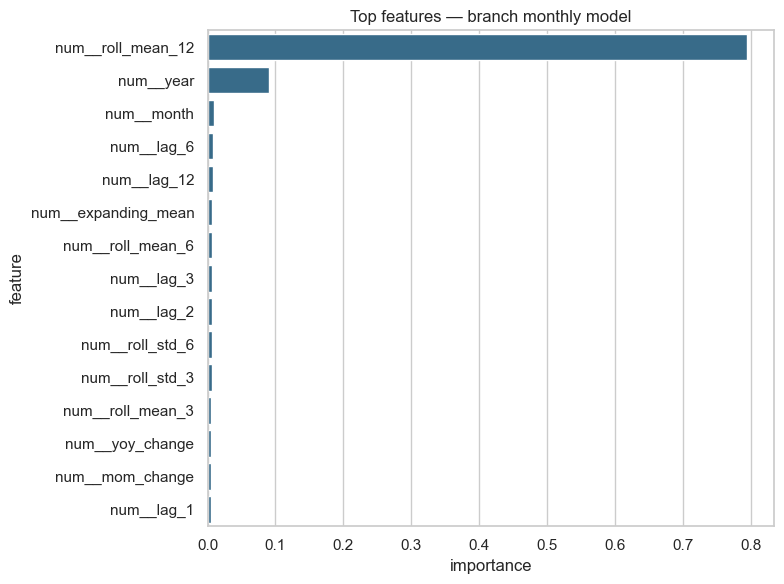

In [19]:
def feature_importance(pipeline, numeric_cols, cat_cols, top=20) -> pd.DataFrame:
    prep = pipeline.named_steps["prep"]
    model = pipeline.named_steps["model"]
    names = prep.get_feature_names_out()
    imp = getattr(model, "feature_importances_", None)
    if imp is None:
        return pd.DataFrame()
    out = pd.DataFrame({"feature": names, "importance": imp}).sort_values("importance", ascending=False)
    return out.head(top)


imp_branch = feature_importance(prod_branch_model, MONTHLY_NUM, MONTHLY_CAT)
imp_branch.to_csv(OUT / "reports" / "feature_importance_branch.csv", index=False)
print(imp_branch.head(15).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(data=imp_branch.head(15), y="feature", x="importance", ax=ax, color="#2a6f97")
ax.set_title("Top features — branch monthly model")
fig.tight_layout()
fig.savefig(OUT / "figures" / "feature_importance_branch.png", dpi=140)
plt.show()


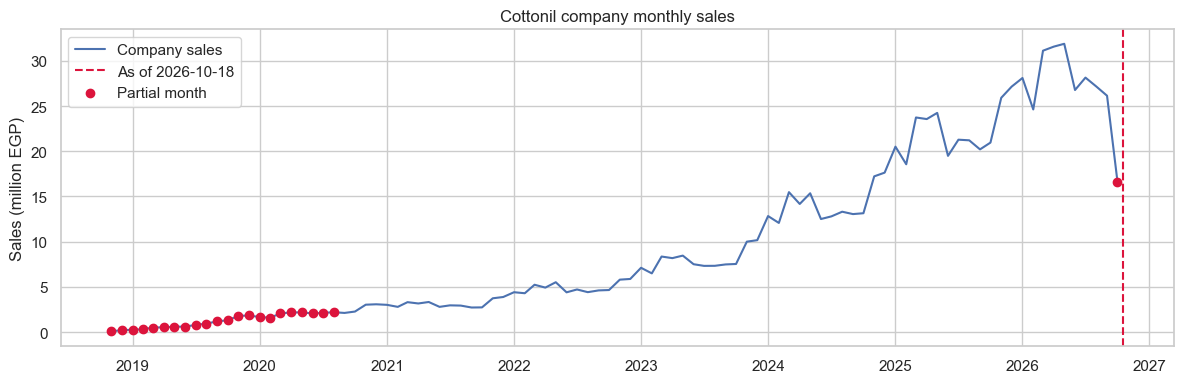

In [20]:
co_plot = monthly_company.copy()
co_plot["month_start"] = co_plot["year_month"].dt.to_timestamp()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(co_plot["month_start"], co_plot["sales_amount"] / 1e6, label="Company sales")
ax.axvline(AS_OF_DATE, color="crimson", ls="--", label=f"As of {AS_OF_DATE.date()}")
partial = co_plot[co_plot["is_partial"]]
ax.scatter(partial["month_start"], partial["sales_amount"] / 1e6, color="crimson", zorder=3, label="Partial month")
ax.set_ylabel("Sales (million EGP)")
ax.set_title("Cottonil company monthly sales")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "figures" / "company_monthly_trend.png", dpi=140)
plt.show()


In [21]:
# Next-month outlook vs previous complete month and same month last year
prev_month = LAST_COMPLETE_MONTH
ly_month = NEXT_MONTH - 12

outlook_rows = []
for bid in ["ALL", *sorted(monthly_branch["branch_id"].unique())]:
    fcst = forecast_next_month(None if bid == "ALL" else bid)
    hist = monthly_all[monthly_all["branch_id"] == bid]
    prev = hist.loc[hist["year_month"] == prev_month, TARGET_GROSS]
    ly = hist.loc[hist["year_month"] == ly_month, TARGET_GROSS]
    prev_v = float(prev.iloc[0]) if len(prev) else np.nan
    ly_v = float(ly.iloc[0]) if len(ly) else np.nan
    yhat = fcst["forecasted_monthly_sales"]
    outlook_rows.append(
        {
            "branch_id": bid,
            "forecast_month": str(NEXT_MONTH),
            "forecast": yhat,
            "prev_complete_month": prev_v,
            "same_month_last_year": ly_v,
            "vs_prev_pct": (yhat / prev_v - 1) * 100 if prev_v else np.nan,
            "vs_ly_pct": (yhat / ly_v - 1) * 100 if ly_v else np.nan,
            "method": fcst["method"],
            "enough_history": fcst["history"]["enough_history"],
        }
    )

outlook = pd.DataFrame(outlook_rows)
outlook.to_csv(OUT / "reports" / "next_month_outlook.csv", index=False)

company_out = outlook.loc[outlook["branch_id"] == "ALL"].iloc[0]
print("Company next-month forecast {:,.0f} EGP".format(company_out["forecast"]))
print("vs previous complete month ({}) {:+.1f}%".format(prev_month, company_out["vs_prev_pct"]))
if pd.notna(company_out["same_month_last_year"]):
    print("vs same month last year ({}) {:+.1f}%".format(ly_month, company_out["vs_ly_pct"]))

branch_out = outlook[outlook["branch_id"] != "ALL"].copy()
print("\nLargest expected increases vs previous month")
print(branch_out.sort_values("vs_prev_pct", ascending=False).head(8)[["branch_id", "forecast", "prev_complete_month", "vs_prev_pct"]].to_string(index=False))
print("\nLargest expected decreases vs previous month")
print(branch_out.sort_values("vs_prev_pct").head(8)[["branch_id", "forecast", "prev_complete_month", "vs_prev_pct"]].to_string(index=False))


Company next-month forecast 32,690,474 EGP
vs previous complete month (2026-09) +25.0%
vs same month last year (2025-11) +26.1%

Largest expected increases vs previous month
branch_id   forecast  prev_complete_month  vs_prev_pct
    BR009 421,847.90           294,079.89        43.45
    BR068 366,774.85           257,344.95        42.52
    BR034 342,806.52           246,404.61        39.12
    BR030 482,063.92           349,671.19        37.86
    BR013 298,406.31           218,796.82        36.39
    BR067 403,578.70           307,512.54        31.24
    BR028 297,961.57           228,334.16        30.49
    BR027 332,877.06           257,675.21        29.18

Largest expected decreases vs previous month
branch_id   forecast  prev_complete_month  vs_prev_pct
    BR061 362,975.61           506,325.28       -28.31
    BR071 376,483.95           513,130.03       -26.63
    BR031 325,908.09           421,852.15       -22.74
    BR007 357,903.95           423,903.61       -15.57
    BR053 

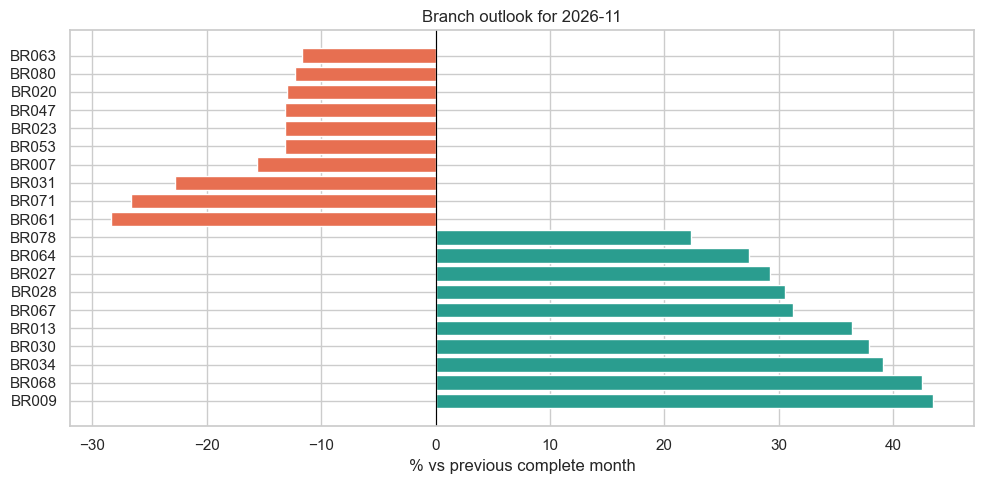

In [22]:
fig, ax = plt.subplots(figsize=(10, 5))
top = pd.concat(
    [
        branch_out.sort_values("vs_prev_pct", ascending=False).head(10),
        branch_out.sort_values("vs_prev_pct").head(10),
    ]
).drop_duplicates("branch_id")
colors = np.where(top["vs_prev_pct"] >= 0, "#2a9d8f", "#e76f51")
ax.barh(top["branch_id"], top["vs_prev_pct"], color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("% vs previous complete month")
ax.set_title(f"Branch outlook for {NEXT_MONTH}")
fig.tight_layout()
fig.savefig(OUT / "figures" / "branch_outlook.png", dpi=140)
plt.show()


In [23]:
eom_company = sample_eom_company
print("Month-end company snapshot")
print("Forecasting date:", eom_company["forecasting_date"])
print("Actual to date: {:,.0f} EGP".format(eom_company["actual_sales_to_date"]))
print("Forecast remaining: {:,.0f} EGP".format(eom_company["forecasted_remaining_sales"]))
print("Expected final: {:,.0f} EGP".format(eom_company["expected_final_monthly_sales"]))

if eom_company["pace_baseline_remaining_sales"] is not None:
    print("Pace-baseline remaining: {:,.0f} EGP".format(eom_company["pace_baseline_remaining_sales"]))

last_full = monthly_company.loc[monthly_company["year_month"] == LAST_COMPLETE_MONTH, TARGET_GROSS].iloc[0]
ly_same = monthly_company.loc[monthly_company["year_month"] == (LATEST_MONTH - 12), TARGET_GROSS]
print("Last complete month total: {:,.0f} EGP".format(last_full))
if len(ly_same):
    print("Same month last year: {:,.0f} EGP".format(float(ly_same.iloc[0])))
    print("Expected final vs last year {:+.1f}%".format(eom_company["expected_final_monthly_sales"] / float(ly_same.iloc[0]) * 100 - 100))


Month-end company snapshot
Forecasting date: 2026-10-18
Actual to date: 16,638,087 EGP
Forecast remaining: 12,165,915 EGP
Expected final: 28,804,002 EGP
Pace-baseline remaining: 12,165,915 EGP
Last complete month total: 26,153,301 EGP
Same month last year: 20,964,627 EGP
Expected final vs last year +37.4%


In [24]:
# Persist a compact inference helper so the two functions can be reused after the notebook is run
artifact = {
    "as_of_date": str(AS_OF_DATE.date()),
    "last_complete_month": str(LAST_COMPLETE_MONTH),
    "next_month": str(NEXT_MONTH),
    "branch_model": selection["branch_model"],
    "company_model": selection["company_model"],
}
(OUT / "reports" / "run_summary.json").write_text(json.dumps(artifact, indent=2))

eval_report = {
    "target": "sales_amount = sum(paid_total_EGP)",
    "as_of_date": str(AS_OF_DATE.date()),
    "splits": {"train_end": str(TRAIN_END), "val_end": str(VAL_END), "test": "after val through last complete month"},
    "selection": selection,
    "comparison": results_df.to_dict(orient="records"),
    "daily_model": daily_results,
    "next_month_company": {k: v for k, v in sample_next_company.items() if k != "daily_predictions"},
    "month_end_company": {k: v for k, v in sample_eom_company.items() if k != "daily_remaining_predictions"},
}
(OUT / "reports" / "evaluation_report.json").write_text(json.dumps(eval_report, indent=2, default=str))
print("Wrote outputs to", OUT)


Wrote outputs to E:\HVIA\cottonil model\outputs


## 11. How to call the forecasts

```python
forecast_next_month()                 # company, next calendar month
forecast_next_month("BR014")          # one branch
forecast_next_month("BR014", return_daily=True)

forecast_month_end()                  # company, latest available month
forecast_month_end("BR014")
```

Saved artifacts:

| Path | Contents |
|---|---|
| `outputs/data/daily_sales.csv` | Cleaned daily branch panel |
| `outputs/data/monthly_sales.csv` | Cleaned monthly branch + company panel |
| `outputs/models/best_branch_monthly.joblib` | Selected branch monthly model |
| `outputs/models/best_company_monthly.joblib` | Selected company monthly model (if ML won) |
| `outputs/models/best_daily.joblib` | Daily remaining-days model |
| `outputs/reports/model_comparison.csv` | MAE / RMSE / MAPE / WAPE |
| `outputs/reports/evaluation_report.json` | Full evaluation + sample forecasts |
| `outputs/figures/` | Trend, importance, and outlook charts |

## 12. Methodology, assumptions, and limitations

### Methodology
1. Aggregate orders to daily and monthly sales by branch using `paid_total_EGP`.
2. Engineer lag/rolling/calendar features that only look backward from the forecast origin.
3. Compare baselines, Random Forest, XGBoost, and (when available) SARIMA and Prophet with a time-based train / validation / test split.
4. Choose the production method with the lowest validation WAPE, including baselines. Tree models are still trained and saved for comparison.
5. Next-month forecasts use the last **complete** month as the most recent lag so a stub month cannot masquerade as full demand.
6. Month-end forecasts use a historical intra-month completion ratio as the primary remaining-sales estimate (daily XGBoost is reported as a comparison because daily noise is high).

### Assumptions
- All provided order statuses are valid sales (no cancelled status exists in the extract).
- Zero-sales days after a branch opens are true zeros, not missing files.
- Ramadan and Eid windows are approximate Gregorian conversions, good enough for monthly seasonality.
- Returns reduce `net_sales` on the refund date; the primary forecast target remains gross collections (`paid_total_EGP`).
- Campaign performance fields are excluded because attributed orders / spend would leak contemporaneous demand.

### Limitations
- The extract ends on the latest `order_date` (partial month). Scenario 2 is an as-of that date, not a live today-clock unless the file is refreshed.
- Strong trend plus seasonality in this extract made a 3-month moving average hard to beat at branch level; RF/XGBoost did not improve validation WAPE over that baseline.
- A global branch model shares strength across stores; very new or very small branches are flagged and may fall back to seasonal naive.
- Recursive daily forecasts can accumulate error over a long remaining horizon.
- SARIMA/Prophet are company-level only; they do not automatically produce coherent branch breakdowns.
- Prices, stockouts, and promotions are not modeled as explicit drivers beyond calendar seasonality.

### Leakage controls
- Lags and rolling means use `shift` / `shift(1)` within `branch_id`.
- Partial latest month is excluded from monthly training labels and from `lag_1` when predicting the next month.
- Daily training labels stop at `AS_OF_DATE`.